# **Part 1: Building simple Convolutional Neural Networks using Pytorch for MNIST dataset**


Completed experiment notebook. Run cells in order. Dependencies: torch, torchvision, numpy, pandas, scikit-learn, matplotlib, gdown, and IPython. All comparisons use seed 42; selected checkpoints minimize validation loss. Test sets are evaluated only after model selection.

**Step 1: Import Required Libraries**

In [1]:
import torch           # Main PyTorch library - provides tensors (like numpy arrays but GPU-compatible)
import torch.nn as nn  # Neural network building blocks: layers (Linear, Conv2d), loss functions (CrossEntropyLoss)
import torch.optim as optim  # Optimization algorithms that update model weights during training like SGD, Adam
import torch.nn.functional as F  # Stateless functions (no learnable parameters) like activation functions (relu, sigmoid), loss functions, pooling
from torch.utils.data import Dataset, DataLoader, random_split  # DataLoader used since PyTorch datasets are often too big for memory
import torchvision.datasets as datasets  # Built-in benchmark datasets ready to download and use like MNIST, CIFAR-10
import torchvision.transforms as transforms # Image preprocessing and augmentation pipelines such as ToTensor()

import numpy as np
from sklearn.model_selection import train_test_split

print("PyTorch version:", torch.__version__)

from pathlib import Path
from copy import deepcopy
import random, time
import pandas as pd
from IPython.display import display, Markdown
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
seed_everything()
torch.set_num_threads(4)
# Prefer GPU where available; CPU remains a supported fallback.
device = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
DATA_ROOT = Path('dataset')
# Use the supplied local data when this completed copy is run from outputs/.
original_root = Path('/Users/arthur/Downloads/Git/cs135-26f-assignments/hw5/dataset')
if not DATA_ROOT.exists() and original_root.exists():
    DATA_ROOT = original_root
print('Device:', device)

: 

**Step 2: Load Data and setup Data Loaders**

The **MNIST dataset** is a collection of handwritten digits commonly used for training various image processing systems. It includes 60,000 training images and 10,000 testing images, each 28x28 pixel grayscale image of the digits 0 through 9. We will train a CNN to classify the label for a grayscale image.

In [ ]:
batch_size = 64

### LOAD DATA ###

# Download the MNIST training set
# transform=transforms.ToTensor() converts images from a Python Image Library format to a PyTorch tensor
full_train_dataset = datasets.MNIST(root=str(DATA_ROOT), train=True, transform=transforms.ToTensor(), download=True)

# Split the 60,000 training images into:
# train_dataset -> 50,000 images used to model weights
# val_dataset -> 10,000 images to monitor performance on unseen data during training
train_dataset, val_dataset = random_split(full_train_dataset, [50000, 10000], generator=torch.Generator().manual_seed(SEED))

# Wrap training set in a DataLoader:
# shuffle=True → randomizes image order every epoch so the model doesn't memorize the sequence
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)

# Wrap validation set in a DataLoader:
# shuffle=False → order doesn't matter for evaluation, and keeping it fixed is more reproducible
val_loader = DataLoader(dataset=val_dataset, batch_size=batch_size, shuffle=False)

# Download the MNIST test set (10,000 images held out until final evaluation)
# train=False → loads the test split (10,000 images)
# The test set is only used ONCE at the very end to report final model performance.
test_dataset = datasets.MNIST(root=str(DATA_ROOT), train=False, transform=transforms.ToTensor(), download=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

# Preserve the MNIST splits before the T-cell section reuses variable names.
mnist_train, mnist_val, mnist_test = train_dataset, val_dataset, test_dataset


  0%|          | 0.00/9.91M [00:00<?, ?B/s]


  4%|▎         | 360k/9.91M [00:00<00:02, 3.56MB/s]


 22%|██▏       | 2.20M/9.91M [00:00<00:00, 12.1MB/s]


 49%|████▊     | 4.82M/9.91M [00:00<00:00, 18.5MB/s]


 76%|███████▌  | 7.50M/9.91M [00:00<00:00, 21.7MB/s]


100%|██████████| 9.91M/9.91M [00:00<00:00, 20.0MB/s]

... (4 outputs left out)


 95%|█████████▌| 1.57M/1.65M [00:00<00:00, 7.28MB/s]


100%|██████████| 1.65M/1.65M [00:00<00:00, 6.77MB/s]


  0%|          | 0.00/4.54k [00:00<?, ?B/s]


100%|██████████| 4.54k/4.54k [00:00<00:00, 13.9MB/s]

Let's visualize what the different classes in the MNIST dataset looks like

Matplotlib is building the font cache; this may take a moment.


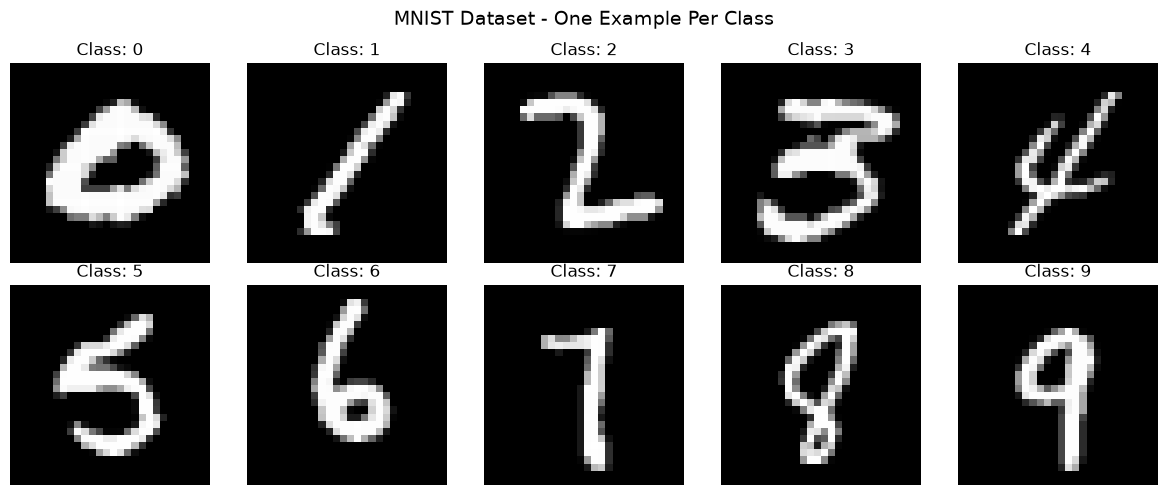

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Get one image per class (0-9)
class_images = {}
for images, labels in train_loader:
    for img, label in zip(images, labels):
        label = label.item()
        if label not in class_images:
            class_images[label] = img
        if len(class_images) == 10:
            break
    if len(class_images) == 10:
        break

# Plot one example per class
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle('MNIST Dataset - One Example Per Class', fontsize=14)

for digit, ax in enumerate(axes.flat):
    img = class_images[digit].squeeze().numpy()
    ax.imshow(img, cmap='gray')
    ax.set_title(f'Class: {digit}')
    ax.axis('off')

plt.tight_layout()
plt.show()

Let's inspect the dimensions of dataset and shape of each image

In [ ]:
# ── DATASET SIZE ─────────────────────────────────────────────────────────────
print(f"Training samples:   {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples:       {len(test_dataset)}")

# ── IMAGE SIZE ───────────────────────────────────────────────────────────────
# Grab a single image and label from the dataset
sample_image, sample_label = full_train_dataset[0]

print(f"\nRaw tensor shape: {sample_image.shape}")   # (C, H, W)
print(f"  Channels: {sample_image.shape[0]}  ← grayscale=1, RGB=3")
print(f"  Height:   {sample_image.shape[1]}  ← pixels")
print(f"  Width:    {sample_image.shape[2]}  ← pixels")
print(f"  Label:    {sample_label}")

# ── HOW THIS MAPS TO THE CNN ──────────────────────────────────────────────────
print(f"\nCNN input settings:")
print(f"  in_channels = {sample_image.shape[0]}  ← matches number of image channels")
print(f"  in_features = {sample_image.shape[0]} × {sample_image.shape[1]} × {sample_image.shape[2]} = {sample_image.shape[0] * sample_image.shape[1] * sample_image.shape[2]}")

Training samples:   50000
Validation samples: 10000
Test samples:       10000

Raw tensor shape: torch.Size([1, 28, 28])
  Channels: 1  ← grayscale=1, RGB=3
  Height:   28  ← pixels
  Width:    28  ← pixels
  Label:    5

CNN input settings:
  in_channels = 1  ← matches number of image channels
  in_features = 1 × 28 × 28 = 784


**Step 3: Create a simple Convolutional Neural Network (CNN) for image classification**

We have provided code below that implements the following CNN for classifying MNIST:

**Architecture**:
        
        Input (1, 28, 28)

        Conv1 → ReLU         (1, 28, 28)  → (8, 28, 28)

        MaxPool              (8, 28, 28)  → (8, 14, 14)

        Conv2 → ReLU         (8, 14, 14)  → (16, 14, 14)

        MaxPool              (16, 14, 14) → (16, 7, 7)
        
        Flatten              (16, 7, 7)   → (784,)

        Fully Connected      (784,)       → (10,)

        Output: 10 raw scores (one per digit class)

In [ ]:
class CNN(nn.Module):
    """
      nn.Module is the base class for all PyTorch models. By inheriting from it we get built-in functionality for tracking parameters,
      saving/loading weights,and moving the model to GPU with .to(device)
    """
    def __init__(self, in_channels=1, num_classes=10):
        """
          __init__ is where all layers are defined and stored as attributes.
          Layers with learnable parameters (Conv2d, Linear) must be defined here
          so PyTorch can track and update their weights during training.

          Args:
            in_channels (int): Number of input channels (1 for grayscale images like MNIST, 3 for RGB like CIFAR-10)
            num_classes (int): The number of output classes (10 for digit recognition 0-9 in MNIST)
        """
        # Always call the parent class constructor first.
        # This initialises PyTorch's internal bookkeeping for parameters and layers
        super(CNN, self).__init__()

        # CONVOLUTIONAL LAYER 1
        # First convolutional layer with 8 filters (or kernels), which applies 3x3 convolution to input image
        # Output shape: (batch, 8, 28, 28)
        self.conv1 = nn.Conv2d(in_channels=in_channels, out_channels=8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))

        # MAX POOLING LAYER
        # Reduces spatial dimensions by taking the maximum value in each 2×2 window.
        # stride=(2,2) means the window moves 2 pixels at a time → halves H and W
        # Applied after BOTH conv1 and conv2:
        #   After conv1: (8,  28, 28) → (8,  14, 14)
        #   After conv2: (16, 14, 14) → (16,  7,  7)
        self.pool = nn.MaxPool2d(kernel_size=(2, 2), stride=(2, 2))

        # CONVOLUTIONAL LAYER 2
        # in_channels=8 must match out_channels of conv1
        # Second convolutional layer with 16 filters, using 3x3 kernels
        # Output shape: (batch, 16, 14, 14)
        self.conv2 = nn.Conv2d(in_channels=8, out_channels=16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))

        # FULLY CONNECTED LAYER
        # After two rounds of conv + pool the feature map is (16, 7, 7).
        # We flatten this into a 1D vector of size 16 × 7 × 7 = 784.
        # This layer maps those 784 features to num_classes (10) output scores,
        # one score per digit class. The highest score is the model's prediction.
        # No activation here — raw scores (logits) are passed to CrossEntropyLoss
        # which applies softmax internally
        self.fc1 = nn.Linear(16 * 7 * 7, num_classes)


    def forward(self, x):
      """
      forward() defines how data flows through the layers defined in __init__.
      PyTorch calls this automatically when you do: output = model(input)
      You should never call forward() directly.

      Args:
            x (tensor): Input batch of images, shape (batch_size, 1, 28, 28)
                        e.g. with batch_size=64: (64, 1, 28, 28)

      Returns:
            x (tensor): Raw class scores (logits), shape (batch_size, 10)
                        These are NOT probabilities yet — pass through softmax
                        to get probabilities, or directly into CrossEntropyLoss

      """
      # BLOCK 1: Conv → ReLU → Pool
      # Apply conv1
      # ReLU sets all negative values to 0, introducing non-linearity so the
      # network can learn complex patterns beyond simple linear transformations.
      # Shape: (batch, 1, 28, 28) → (batch, 8, 28, 28)
      x = F.relu(self.conv1(x))

      # MaxPool halves the spatial dimensions to reduce computation
      # Shape: (batch, 8, 28, 28) → (batch, 8, 14, 14)
      x = self.pool(x)

      # BLOCK 2: Conv → ReLU → Pool
      # Apply conv2
      # Shape: (batch, 8, 14, 14) → (batch, 16, 14, 14)
      x = F.relu(self.conv2(x))

      # MaxPool again halves spatial dimensions
      # Shape: (batch, 16, 14, 14) → (batch, 16, 7, 7)
      x = self.pool(x)

      # FLATTEN
      # Reshape the 3D feature map into a 1D vector per image in the batch.
      # x.shape[0] preserves the batch dimension.
      # -1 tells PyTorch to infer the remaining size: 16 × 7 × 7 = 784
      # Shape: (batch, 16, 7, 7) → (batch, 784)
      x = x.reshape(x.shape[0], -1)

      # FULLY CONNECTED
      # Map the 784 learned features to 10 output scores (one per digit class).
      # The class with the highest score is the model's predicted digit.
      # Shape: (batch, 784) → (batch, 10)
      x = self.fc1(x)

      # Return raw logits — CrossEntropyLoss expects these directly
      return x

In [ ]:
# Training and Validation functions

def train_step(model, data, targets, loss_fn, optimizer):
  """
    Performs one mini-batch update during training:
        1. Forward pass  → compute predictions and loss
        2. Backward pass → compute gradients via backpropagation
        3. Weight update → optimizer adjusts model parameters

    Args:
        model     : The CNN model being trained
        data      : One batch of input images,  shape (batch_size, 1, 28, 28)
        targets   : One batch of true labels,   shape (batch_size,)
        loss_fn   : Loss function e.g. nn.CrossEntropyLoss()
        optimizer : Optimizer e.g. optim.Adam()

    Returns:
        loss.item()  : Scalar loss value for this batch (plain Python float, not a tensor)
        num_correct  : Number of correct predictions in this batch
        num_samples  : Total number of samples in this batch (usually = batch_size)
  """
  model.train() # Set the model to training mode. This enables layers that behave differently during training vs evaluation

  # MOVE DATA TO DEVICE
  # PyTorch requires ALL tensors involved in a computation to be on the SAME device.
  # .to(device) moves the tensor to whichever device was set earlier
  data = data.to(device=device)
  targets = targets.to(device=device)

  # FORWARD PASS
  # Pass the batch of images through the model.
  # Internally calls model.forward(data) and returns raw class scores (logits)
  # Shape: (batch_size, num_classes) e.g. (64, 10) for MNIST
  scores = model(data)

  # Compute how wrong the model's predictions are compared to the true labels.
  # CrossEntropyLoss applies softmax to scores internally, then computes
  # negative log likelihood. Returns a single scalar value averaged over the batch.
  loss = loss_fn(scores, targets)

  # BACKWARD PASS
  optimizer.zero_grad()  # set all gradients to zero for each batch bc by default, gradients are accumulated in PyTorch
  loss.backward() # backpropagation to compute gradient of the loss with respect to all trainable parameters in the model

  # gradient descent
  optimizer.step() # optimizer updates model parameters using gradients computed during backpropagation

  # Accumulate loss and accuracy
  _, predictions = scores.max(1)
  num_correct = (predictions == targets).sum().item()
  num_samples = predictions.size(0)

  return loss.item(), num_correct, num_samples


def validation_step(model, data, targets, loss_fn):
  """
    Performs one mini-batch evaluation during validation.
    No gradient computation or weight updates occur here —
    we are only measuring how well the model generalises to unseen data.

    Args:
        model   : The CNN model being evaluated
        data    : One batch of input images,  shape (batch_size, 1, 28, 28)
        targets : One batch of true labels,   shape (batch_size,)
        loss_fn : Loss function e.g. nn.CrossEntropyLoss()

    Returns:
        loss.item()           : Scalar loss value for this batch
        num_correct           : Number of correct predictions in this batch
        num_samples           : Total samples in this batch
  """
  model.eval() # Set the model to evaluation mode

  # Move batch to the same device as the model
  data = data.to(device=device)
  targets = targets.to(device=device)

  # During validation we never call loss.backward(), so gradients are unnecessary.
  with torch.no_grad(): # Disable gradient calculation for validation

    # Forward pass only — no backward pass or weight update
    scores = model(data)
    loss = loss_fn(scores, targets)

    # Same accuracy calculation as train_step
    _, predictions = scores.max(1)
    num_correct = (predictions == targets).sum().item()
    num_samples = predictions.size(0)

  return loss.item(), num_correct, num_samples



In [ ]:
# DEVICE SETUP
# device was selected in the imports cell

# HYPERPARAMETERS
in_channel = 1
num_classes = 10 # MNIST has 10 classes (one for each digit from 0 to 9)
learning_rate = 0.001 # step size used for each iteration
batch_size = 64

# INITIALISE NETWORK
model = CNN().to(device)

# LOSS FUNCTION
loss_fn = nn.CrossEntropyLoss()

# OPTIMIZER
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

Train for a certain number of epochs, 5 epochs can take about 1 minute to run

In [ ]:
# -------- TRACKING METRICS ---------
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

EPOCHS = 5

# -------- TRAINING LOOP -----------
for epoch in range(EPOCHS):
  # Training accumulators
  running_loss = 0.0 # sum of batch losses across the epoch
  num_correct = 0    # total correct predictions across all training batches
  num_samples = 0    # total samples seen across all training batches

  # Validation accumulators — separate from training so metrics don't mix
  val_running_loss = 0.0
  val_num_correct = 0
  val_num_samples = 0

  # TRAINING PHASE: Iterate over every mini-batch in the training set.
  # enumerate() gives us batch_idx (the batch number) and the batch itself
  # (data, targets) where:
  #   data    → image tensors, shape (batch_size, 1, 28, 28)
  #   targets → true digit labels, shape (batch_size,)
  # One full pass through train_loader = one epoch of training
  for batch_idx, (data, targets) in enumerate(train_loader):
    # train_step performs forward pass, loss computation, backpropagation, and weight update for this single batch
    loss, num_corr, num_sam = train_step(model, data, targets, loss_fn, optimizer)
    running_loss += loss * num_sam
    num_correct += num_corr
    num_samples += num_sam

  # VALIDATION PHASE: After all training batches are done, evaluate on the validation set.
  for batch_idx, (data, targets) in enumerate(val_loader):
    loss, num_corr, num_sam = validation_step(model, data, targets, loss_fn)
    val_running_loss += loss * num_sam
    val_num_correct += num_corr
    val_num_samples += num_sam

  # EPOCH-LEVEL METRICS
  epoch_loss = running_loss / num_samples # Sample-weighted mean loss
  epoch_acc = float(num_correct) / float(num_samples) * 100

  # Append epoch averages to history lists for plotting later
  train_losses.append(epoch_loss)
  train_accuracies.append(epoch_acc)

  # Same averaging for validation metrics
  val_epoch_loss = val_running_loss / val_num_samples
  val_epoch_acc = float(val_num_correct) / float(val_num_samples) * 100

  val_losses.append(val_epoch_loss)
  val_accuracies.append(val_epoch_acc)

  print(
      f'Epoch {epoch+1}, '
      f'Loss: {epoch_loss:0.2f}, '
      f'Train Acc: {epoch_acc:0.2f}, '
      f'Val Loss: {val_epoch_loss:0.2f}, '
      f'Val Acc: {val_epoch_acc:0.2f}'
  )

Epoch 1, Loss: 0.35, Train Acc: 89.75, Val Loss: 0.13, Val Acc: 95.99


Epoch 2, Loss: 0.10, Train Acc: 97.14, Val Loss: 0.08, Val Acc: 97.63


Epoch 3, Loss: 0.08, Train Acc: 97.74, Val Loss: 0.07, Val Acc: 97.75


Epoch 4, Loss: 0.06, Train Acc: 98.10, Val Loss: 0.06, Val Acc: 98.03


Epoch 5, Loss: 0.05, Train Acc: 98.33, Val Loss: 0.06, Val Acc: 97.95


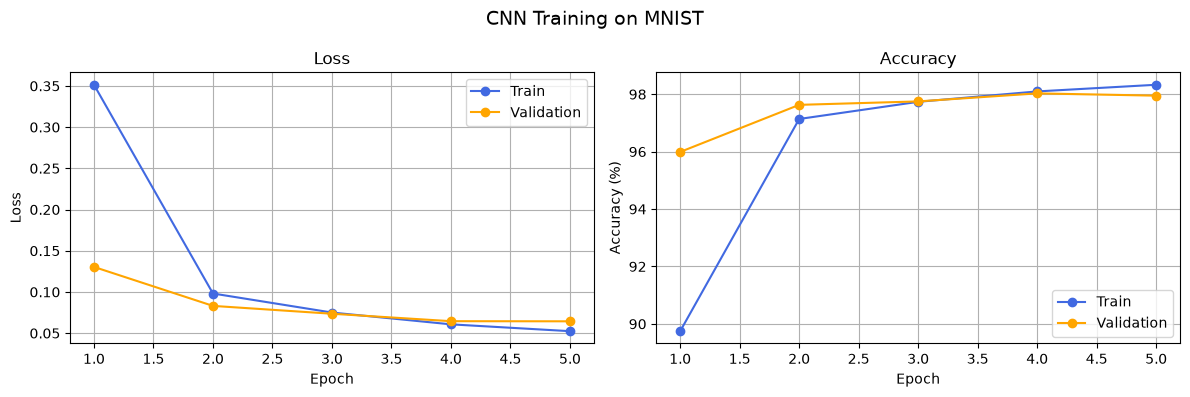

In [ ]:
# ---- Plot Training Curves ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('CNN Training on MNIST', fontsize=14)

ax1.plot(range(1, EPOCHS+1), train_losses, marker='o', color='royalblue', label='Train')
ax1.plot(range(1, EPOCHS+1), val_losses,   marker='o', color='orange', label='Validation')
ax1.set_title('Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(range(1, EPOCHS+1), train_accuracies, marker='o', color='royalblue', label='Train')
ax2.plot(range(1, EPOCHS+1), val_accuracies,   marker='o', color='orange',    label='Validation')

ax2.set_title('Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Test evaluation is deferred until after Problem 1B so it cannot influence tuning.

# **Problem 1**: Experiment with the CNN model and the MNIST dataset. Please do the following:

**Part a:** Try out different optimizers with the initial hyperparameters found in the starter notebook. Discuss the effects of the different optimizers, which one you think performs the best on MNIST, and why.




SGD lr=0.001 batch=64: epoch  1/5, train loss=2.2941, val loss=2.2776, val acc=26.39%


SGD lr=0.001 batch=64: epoch  2/5, train loss=2.2407, val loss=2.1830, val acc=53.17%


SGD lr=0.001 batch=64: epoch  3/5, train loss=2.0113, val loss=1.7102, val acc=72.68%


SGD lr=0.001 batch=64: epoch  4/5, train loss=1.2034, val loss=0.8120, val acc=80.32%


SGD lr=0.001 batch=64: epoch  5/5, train loss=0.6489, val loss=0.5586, val acc=84.48%


RMSprop lr=0.001 batch=64: epoch  1/5, train loss=0.2505, val loss=0.1599, val acc=95.18%


... (6 outputs left out)

Adam lr=0.001 batch=64: epoch  3/5, train loss=0.0818, val loss=0.0883, val acc=97.48%


Adam lr=0.001 batch=64: epoch  4/5, train loss=0.0675, val loss=0.0732, val acc=97.91%


Adam lr=0.001 batch=64: epoch  5/5, train loss=0.0580, val loss=0.0682, val acc=98.00%


,best_epoch,train_loss,train_acc,val_loss,val_acc,seconds
RMSprop,5.0,0.0425,98.752,0.0616,98.12,40.5191
Adam,5.0,0.0473,98.564,0.0682,98.00,40.6820
SGD,5.0,0.5462,84.958,0.5586,84.48,40.3153


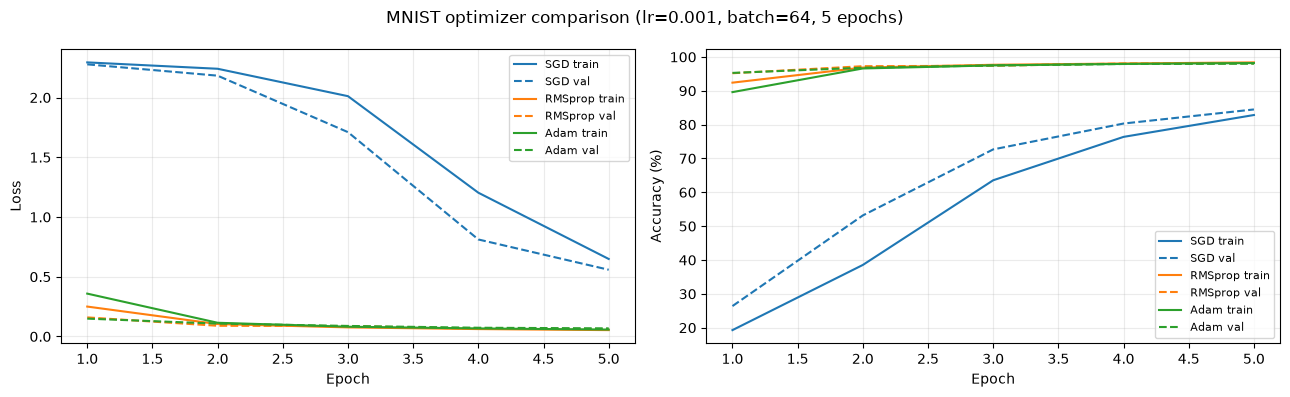

**1A discussion.** With the same split, initialization, learning rate (0.001), batch size (64), and five-epoch budget, **RMSprop** had the lowest validation loss (0.0616) and validation accuracy 98.12%. I therefore select it. SGD uses a single fixed step scale; RMSprop adapts steps using squared-gradient averages; Adam combines adaptive scaling with momentum. Adaptive methods can converge faster under this short budget. This comparison identifies the best setting in this experiment, not the universally best optimizer: SGD may need a different learning rate or more epochs.

In [ ]:
# Shared experiment utilities: sample-weighted losses, deterministic restarts,
# validation-only checkpoint selection, and no test-set use during tuning.
def run_epoch(model, loader, criterion, optimizer=None, binary=False):
    model.train(optimizer is not None)
    total_loss = correct = count = 0
    with torch.set_grad_enabled(optimizer is not None):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if optimizer is not None:
                optimizer.zero_grad(set_to_none=True)
            out = model(x)
            loss = criterion(out, y)
            if optimizer is not None:
                loss.backward()
                optimizer.step()
            predictions = (out >= 0.5).to(y.dtype) if binary else out.argmax(1)
            total_loss += loss.item() * len(x)
            correct += (predictions == y).sum().item()
            count += len(x)
    return total_loss / count, 100 * correct / count

def fit_experiment(factory, train_data, val_data, optimizer_name='Adam',
                   lr=0.001, batch_size=64, epochs=5, binary=False, weight_decay=0):
    seed_everything()
    net = factory().to(device)
    train_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
    val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False)
    criterion = nn.BCELoss() if binary else nn.CrossEntropyLoss()
    opt = getattr(optim, optimizer_name)(net.parameters(), lr=lr, weight_decay=weight_decay)
    history = []
    best_loss, best_state, best_epoch = float('inf'), None, 0
    start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(net, train_dl, criterion, opt, binary)
        va_loss, va_acc = run_epoch(net, val_dl, criterion, binary=binary)
        history.append(dict(epoch=epoch, train_loss=tr_loss, train_acc=tr_acc,
                            val_loss=va_loss, val_acc=va_acc))
        if va_loss < best_loss:
            best_loss, best_epoch = va_loss, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
        print(f'{optimizer_name} lr={lr:g} batch={batch_size}: epoch {epoch:2d}/{epochs}, '
              f'train loss={tr_loss:.4f}, val loss={va_loss:.4f}, val acc={va_acc:.2f}%', flush=True)
    net.load_state_dict(best_state)
    # Comparable train/validation metrics for the selected checkpoint (evaluation mode).
    tr_loss, tr_acc = run_epoch(net, DataLoader(train_data, batch_size=batch_size), criterion, binary=binary)
    va_loss, va_acc = run_epoch(net, val_dl, criterion, binary=binary)
    return dict(model=net, history=pd.DataFrame(history), best_epoch=best_epoch,
                train_loss=tr_loss, train_acc=tr_acc, val_loss=va_loss, val_acc=va_acc,
                seconds=time.perf_counter()-start)

def plot_histories(results, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for name, result in results.items():
        h = result['history']
        for ax, metric in zip(axes, ['loss', 'acc']):
            line, = ax.plot(h.epoch, h['train_'+metric], label=name+' train')
            ax.plot(h.epoch, h['val_'+metric], '--', color=line.get_color(), label=name+' val')
    for ax, label in zip(axes, ['Loss', 'Accuracy (%)']):
        ax.set(xlabel='Epoch', ylabel=label)
        ax.grid(alpha=.25)
        ax.legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

def results_table(results):
    return pd.DataFrame({name: {k:r[k] for k in
        ['best_epoch','train_loss','train_acc','val_loss','val_acc','seconds']}
        for name,r in results.items()}).T.sort_values('val_loss')

optimizer_results = {}
for name in ['SGD', 'RMSprop', 'Adam']:
    optimizer_results[name] = fit_experiment(CNN, mnist_train, mnist_val, optimizer_name=name)
optimizer_table = results_table(optimizer_results)
display(optimizer_table.round(4))
plot_histories(optimizer_results, 'MNIST optimizer comparison (lr=0.001, batch=64, 5 epochs)')
best_optimizer = optimizer_table.index[0]
display(Markdown(f'**1A discussion.** With the same split, initialization, learning rate (0.001), '
    f'batch size (64), and five-epoch budget, **{best_optimizer}** had the lowest validation '
    f'loss ({optimizer_table.iloc[0].val_loss:.4f}) and validation accuracy '
    f'{optimizer_table.iloc[0].val_acc:.2f}%. I therefore select it. '
    'SGD uses a single fixed step scale; RMSprop adapts steps using squared-gradient averages; '
    'Adam combines adaptive scaling with momentum. Adaptive methods can converge faster under '
    'this short budget. This comparison identifies the best setting in this experiment, '
    'not the universally best optimizer: SGD may need a different learning rate or more epochs.'))

**Part b: Batch Size and Learning Rate**
Given the best optimizer you found, experiment with batch size and learning rate.

RMSprop lr=0.0001 batch=32: epoch  1/5, train loss=0.8062, val loss=0.3688, val acc=89.22%


RMSprop lr=0.0001 batch=32: epoch  2/5, train loss=0.2960, val loss=0.2673, val acc=92.09%


RMSprop lr=0.0001 batch=32: epoch  3/5, train loss=0.2281, val loss=0.2152, val acc=93.64%


RMSprop lr=0.0001 batch=32: epoch  4/5, train loss=0.1886, val loss=0.1849, val acc=94.52%


RMSprop lr=0.0001 batch=32: epoch  5/5, train loss=0.1619, val loss=0.1590, val acc=95.05%


RMSprop lr=0.001 batch=32: epoch  1/5, train loss=0.2140, val loss=0.1145, val acc=96.53%


... (31 outputs left out)

RMSprop lr=0.01 batch=128: epoch  3/5, train loss=0.0961, val loss=0.1192, val acc=96.38%


RMSprop lr=0.01 batch=128: epoch  4/5, train loss=0.0833, val loss=0.1367, val acc=95.87%


RMSprop lr=0.01 batch=128: epoch  5/5, train loss=0.0788, val loss=0.0865, val acc=97.49%


,best_epoch,train_loss,train_acc,val_loss,val_acc,seconds
"batch=32, lr=0.001",4.0,0.0434,98.722,0.0616,98.09,45.0277
"batch=64, lr=0.001",5.0,0.0425,98.752,0.0616,98.12,40.5191
"batch=128, lr=0.001",5.0,0.0579,98.248,0.0749,97.68,38.4338
"batch=32, lr=0.01",2.0,0.0710,97.714,0.0845,97.23,44.1349
"batch=128, lr=0.01",5.0,0.0652,97.940,0.0865,97.49,38.7183
"batch=64, lr=0.01",5.0,0.0702,97.740,0.0873,97.41,40.6019
"batch=32, lr=0.0001",5.0,0.1475,95.618,0.1590,95.05,47.2235
"batch=64, lr=0.0001",5.0,0.1897,94.376,0.2020,93.87,40.0380
"batch=128, lr=0.0001",5.0,0.2504,92.634,0.2644,92.11,38.5040


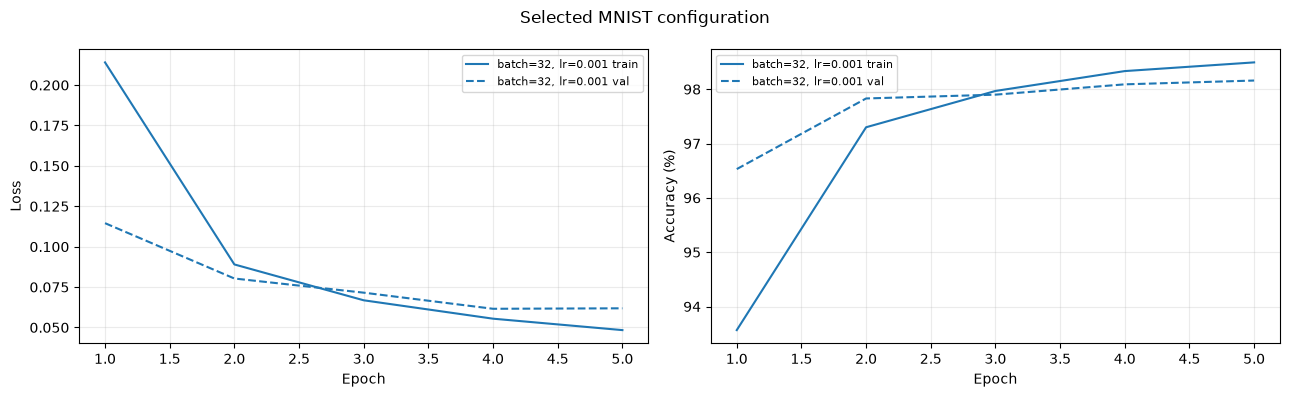

Final MNIST test loss: 0.0452; accuracy: 98.47%


**1B discussion.** I selected **RMSprop, batch=32, lr=0.001**, using minimum validation loss: 0.0616, with 98.09% validation accuracy. The final test accuracy is 98.47%. Smaller batches make more updates per epoch but have noisier gradients; larger batches make fewer updates, so equal epochs are not equal optimizer steps. A low learning rate can learn too slowly, while a large one may overshoot. The grid above shows the measured trade-off. All choices were made before this single final test evaluation.

In [ ]:
# A small full factorial grid; reuse the identical baseline instead of rerunning it.
tuning_results = {}
for bs in [32, 64, 128]:
    for lr in [0.0001, 0.001, 0.01]:
        key = f'batch={bs}, lr={lr:g}'
        tuning_results[key] = (optimizer_results[best_optimizer] if (bs, lr)==(64, 0.001)
            else fit_experiment(CNN, mnist_train, mnist_val, best_optimizer, lr, bs))
tuning_table = results_table(tuning_results)
display(tuning_table.round(4))
best_setting = tuning_table.index[0]
mnist_final = tuning_results[best_setting]
plot_histories({best_setting: mnist_final}, 'Selected MNIST configuration')
mnist_test_loss, mnist_test_acc = run_epoch(mnist_final['model'],
    DataLoader(mnist_test, batch_size=64, shuffle=False), nn.CrossEntropyLoss())
print(f'Final MNIST test loss: {mnist_test_loss:.4f}; accuracy: {mnist_test_acc:.2f}%')
display(Markdown(f'**1B discussion.** I selected **{best_optimizer}, {best_setting}**, '
    f'using minimum validation loss: {mnist_final["val_loss"]:.4f}, with '
    f'{mnist_final["val_acc"]:.2f}% validation accuracy. The final test accuracy is '
    f'{mnist_test_acc:.2f}%. Smaller batches make more updates per epoch but have noisier '
    'gradients; larger batches make fewer updates, so equal epochs are not equal optimizer steps. '
    'A low learning rate can learn too slowly, while a large one may overshoot. The grid above '
    'shows the measured trade-off. All choices were made before this single final test evaluation.'))

**Observed batch-size and learning-rate effects.** A learning rate of 0.001 had the lowest validation loss at every batch size. At 0.0001, increasing batch size from 32 to 128 reduced validation accuracy from 95.05% to 92.11%, consistent with slower progress from fewer updates. A learning rate of 0.01 reached 97.23–97.49%, but had higher validation loss than 0.001. Batch sizes 32 and 64 were nearly tied at 0.001: their losses both round to 0.0616, and selection used the unrounded values. Batch size 64 had slightly higher validation accuracy, but minimum validation loss was the selection criterion throughout. These tiny differences should not be treated as strong evidence of superiority.

# **Part 2: T-Cell Image Data Classification**

**Immunotherapy** is a cancer treatment that harnesses the body's own immune cells to attack tumors. T-cells are an important part of the immune system and a common target for immunotherapy. However, for most immunotherapy treatments that target T-cells to be effective, the T-cells used must be in an active state. Being able to quickly and accurately classify T-cells by activation state is therefore critical to the success of many immunotherapy treatments.

Our goal is to classify the grayscale image of a single T-cell as **Active** (capable of attacking cancer cells, selected for treatment) or **Quiecent** (inactive, discarded from the treatment pipeline). This is a **binary image classification** problem.

More information about this dataset can be found [here](https://carpentries-incubator.github.io/ml4bio-workshop/02-T-cells/index.html).

**Step 1: Download T-Cell Image Data**

The data was stored on a Google drive which can be downloaded inside a notebook.

In [ ]:
# Reuse local CSVs; download the assignment-provided files only if missing.
import gdown
TCELL_ROOT = Path('dataset/tcells')
TCELL_ROOT.mkdir(parents=True, exist_ok=True)
for filename, file_id in [('X_train.csv', '1zg0hRua1RWqR2EFwVzChK3sVNKkctNh9'),
                          ('y_train.csv', '1_g_8dLvjLb277snQ-EEDDRvSSVkmnsvN')]:
    target = TCELL_ROOT / filename
    if not target.exists():
        gdown.download(id=file_id, output=str(target), quiet=False)
    if not target.exists():
        raise FileNotFoundError(f'Place {filename} in {TCELL_ROOT.resolve()} and rerun.')

In [ ]:
X = np.loadtxt(TCELL_ROOT / 'X_train.csv')
y = np.loadtxt(TCELL_ROOT / 'y_train.csv').reshape(-1)
assert X.shape == (len(y), 78*78)
assert set(np.unique(y)) == {0, 1}
assert np.isfinite(X).all() and X.min() >= 0 and X.max() <= 255
# Stratification keeps both classes represented; test data stays untouched until selection.
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.2, random_state=42, stratify=y_dev)
print(f'T-cell samples: train={len(y_train)}, validation={len(y_val)}, test={len(y_test)}')
print('Training label counts:', dict(zip(*np.unique(y_train, return_counts=True))))

T-cell samples: train=484, validation=122, test=68
Training label counts: {np.float64(0.0): np.int64(315), np.float64(1.0): np.int64(169)}


**Step 2: Reshape and normalize the data**

In [ ]:
X_train = X_train/255.0
X_val = X_val/255.0
X_test = X_test/255.0

In [ ]:
print(X_train.shape)

X_train = X_train.reshape((-1, 1, 78, 78)).astype('float32') # Reshape for PyTorch (batch, channels, height, width)
X_val = X_val.reshape((-1, 1, 78, 78)).astype('float32')
X_test = X_test.reshape((-1, 1, 78, 78)).astype('float32')

(484, 6084)


**Step 3: Create PyTorch datasets/batches**

In [ ]:
class TCellDataset(Dataset):
  def __init__(self, features, labels):
    self.features = torch.tensor(features, dtype=torch.float32)
    self.labels = torch.tensor(labels, dtype=torch.float32).unsqueeze(1) # Add channel dimension for labels

  def __len__(self):
    return len(self.labels)

  def __getitem__(self, idx):
    return self.features[idx], self.labels[idx]

train_dataset = TCellDataset(X_train, y_train)
val_dataset = TCellDataset(X_val, y_val)

BATCH_SIZE = 32
train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

#**Problem 2: Simple PyTorch CNN Model for T-cell binary image classification**

**Complete the CNN class with the following architeture for the t-cell dataset.** You can follow along the subtasks listed in the incomplete code below.  Make sure to look into the size of the images in the data set to help determine the dimensions of the different layers.


**Architecture:**

Input image (1 channel, 78x78)

Conv Layer 1 -> ReLU -> MaxPool

Conv Layer 2 -> ReLU

Flatten

Fully Connected 1 -> ReLU

Fully Connected 2 -> ReLU

Output (1 neuron) -> Sigmoid




In [ ]:
class SimpleCNN(nn.Module):
  def __init__(self):
    super().__init__()
    # Subtask 1: Create a 2D convolution layer
    #   - Input channels:  1  (grayscale image)
    #   - Output channels: 16 (number of filters to learn)
    #   - Kernel size:     5  (5×5 filter)
    #   - Padding:        'same' (output H and W stay the same as input)
    self.conv1 = nn.Conv2d(1, 16, kernel_size=5, padding=2)

    # Subtask 2: Add a ReLU activation
    self.relu1 = nn.ReLU()

    # Subtask 3: Add a MaxPool layer to halve the spatial dimensions
    #   - Kernel size: 2
    #   - Stride:      2
    #   Hint: After this layer a 78×78 image becomes 39×39
    self.maxpool1 = nn.MaxPool2d(2, 2)

    # Subtask 4: Create a second 2D convolution layer
    #   - Input channels:  16 (must match output of conv1)
    #   - Output channels: 8  (we reduce the number of filters)
    #   - Kernel size:     3
    #   - Padding:        'same'
    self.conv2 = nn.Conv2d(16, 8, kernel_size=3, padding=1)

    # Subtask 5: Add a ReLU activation
    self.relu2 = nn.ReLU()

    # Subtask 6: Add a Flatten layer to convert the 3D feature map to 1D
    # Hint: After conv2 the feature map is (8, 39, 39) so the flattened size is 8 × 39 × 39 = 12168
    self.flatten = nn.Flatten()

    # FULLY CONNECTED LAYERS
    # Subtask 7: Add a Linear layer
    #   - Input features:  8 * 39 * 39 = 12168
    #   - Output features: 24
    self.d1 = nn.Linear(8 * 39 * 39, 24)

    # Subtask 8: Add a ReLU activation
    self.relu3 = nn.ReLU()

    # Subtask 9: Add a Linear layer
    #   - Input features:  24
    #   - Output features: 6
    self.d2 = nn.Linear(24, 6)

    # Subtask 10: Add a ReLU activation
    self.relu4 = nn.ReLU()

    # OUTPUT LAYER
    # Subtask 11: Add the final Linear layer
    #   - Input features:  6
    #   - Output features: 1  (binary classification → single probability)
    self.pred = nn.Linear(6, 1)

    # Subtask 12: Add a Sigmoid activation to squash output between 0 and 1
    self.sigmoid = nn.Sigmoid()

  def forward(self, x):
    """
        Define the forward pass by connecting layers in order.
        Each task below corresponds to applying one layer to x.

        Hint: the pattern is always  x = self.layer(x)
    """

    # Subtask 13: Pass x through conv1, then relu1, then maxpool1
    x = self.maxpool1(self.relu1(self.conv1(x)))

    # Subtask 14: Pass x through conv2, then relu2
    x = self.relu2(self.conv2(x))

    # Subtask 15: Flatten x
    x = self.flatten(x)

    # Subtask 16: Pass x through d1, then relu3
    x = self.relu3(self.d1(x))

    # Subtask 17: Pass x through d2, then relu4
    x = self.relu4(self.d2(x))

    # Subtask 18: Return the sigmoid of pred(x)
    return self.sigmoid(self.pred(x))

#**Problem 3: T-Cell Image Classification with Binary CNN**

**Part a**: Use the template from the CNN MNIST example to define the loss function (BCE), optimizer and set up a training and validation loop with the simple binary CNN you just developed and apply this to the T-Cell Image data set. Please train your model for at least 15 epochs and graph the training + validation loss and accuracies.
Use the following hyperparameters:

1.   batch size = 32
2.   loss function = BCELoss
3.   optimizer = Adam optimizer
4.   learning rate = 0.001


Adam lr=0.001 batch=32: epoch  1/15, train loss=0.6885, val loss=0.6511, val acc=65.57%


Adam lr=0.001 batch=32: epoch  2/15, train loss=0.6279, val loss=0.6005, val acc=66.39%


Adam lr=0.001 batch=32: epoch  3/15, train loss=0.5801, val loss=0.5253, val acc=79.51%


Adam lr=0.001 batch=32: epoch  4/15, train loss=0.5079, val loss=0.4187, val acc=82.79%


Adam lr=0.001 batch=32: epoch  5/15, train loss=0.4242, val loss=0.3689, val acc=85.25%


Adam lr=0.001 batch=32: epoch  6/15, train loss=0.3940, val loss=0.3417, val acc=86.89%


... (5 outputs left out)

Adam lr=0.001 batch=32: epoch 12/15, train loss=0.3312, val loss=0.3750, val acc=82.79%


Adam lr=0.001 batch=32: epoch 13/15, train loss=0.3441, val loss=0.3782, val acc=84.43%


Adam lr=0.001 batch=32: epoch 14/15, train loss=0.3422, val loss=0.2656, val acc=89.34%


Adam lr=0.001 batch=32: epoch 15/15, train loss=0.2902, val loss=0.2561, val acc=92.62%


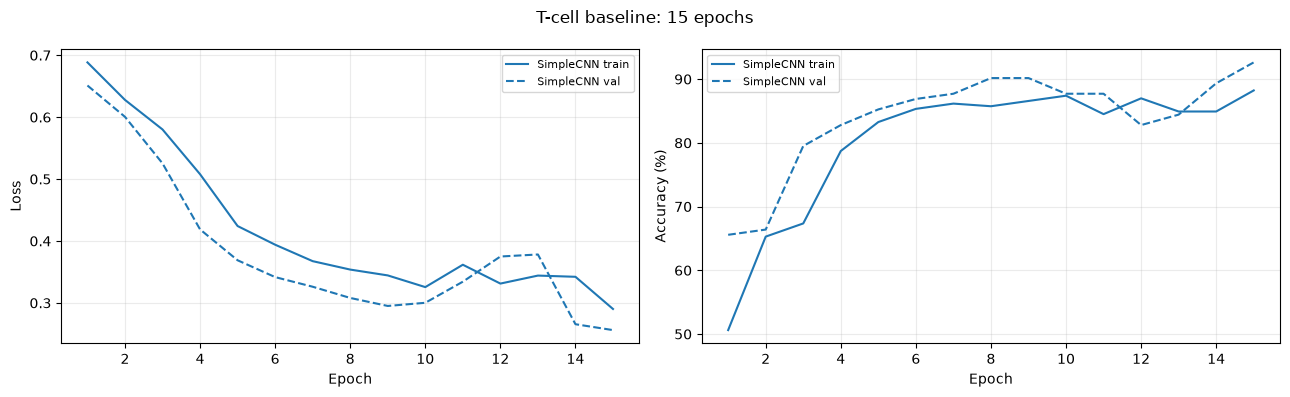

,best_epoch,train_loss,train_acc,val_loss,val_acc,seconds
SimpleCNN,15.0,0.2821,89.0496,0.2561,92.623,8.4817


In [ ]:
# Required architecture and hyperparameters; train all 15 epochs.
with torch.no_grad():
    example_output = SimpleCNN()(torch.zeros(2, 1, 78, 78))
assert example_output.shape == (2, 1)
assert ((example_output >= 0) & (example_output <= 1)).all()
tcell_baseline = fit_experiment(SimpleCNN, train_dataset, val_dataset,
    optimizer_name='Adam', lr=0.001, batch_size=32, epochs=15, binary=True)
plot_histories({'SimpleCNN': tcell_baseline}, 'T-cell baseline: 15 epochs')
display(results_table({'SimpleCNN': tcell_baseline}).round(4))

**Part b**:
Experiment with the architecture of the CNN model. You may but are not required to also vary any hyperparameters you desire. You do not need to by systematic explore a set of networks, alter the layers and try to get a feel for what works best in this scenario. However, **only calculate test accuracy after you choose a final architecture**. Report what you found to work best, training and validation loss, and the testing AUCROC of the final model you choose.

Adam lr=0.001 batch=32: epoch  1/15, train loss=0.6520, val loss=0.6388, val acc=65.57%


Adam lr=0.001 batch=32: epoch  2/15, train loss=0.6291, val loss=0.6079, val acc=65.57%


Adam lr=0.001 batch=32: epoch  3/15, train loss=0.5868, val loss=0.5230, val acc=77.87%


Adam lr=0.001 batch=32: epoch  4/15, train loss=0.4976, val loss=0.4345, val acc=83.61%


Adam lr=0.001 batch=32: epoch  5/15, train loss=0.4307, val loss=0.4791, val acc=80.33%


Adam lr=0.001 batch=32: epoch  6/15, train loss=0.4344, val loss=0.3990, val acc=81.97%


... (21 outputs left out)

Adam lr=0.001 batch=32: epoch 13/15, train loss=0.3987, val loss=0.3583, val acc=86.07%


Adam lr=0.001 batch=32: epoch 14/15, train loss=0.3912, val loss=0.3598, val acc=87.70%


Adam lr=0.001 batch=32: epoch 15/15, train loss=0.4111, val loss=0.3978, val acc=84.43%


,best_epoch,train_loss,train_acc,val_loss,val_acc,seconds,parameters
SimpleCNN,15.0,0.2821,89.0496,0.2561,92.6230,8.4817,293789
Extra pooling,13.0,0.3424,86.5702,0.3317,86.8852,8.2486,71069
Pooling + regularization,13.0,0.3668,85.1240,0.3583,86.0656,8.4595,71069


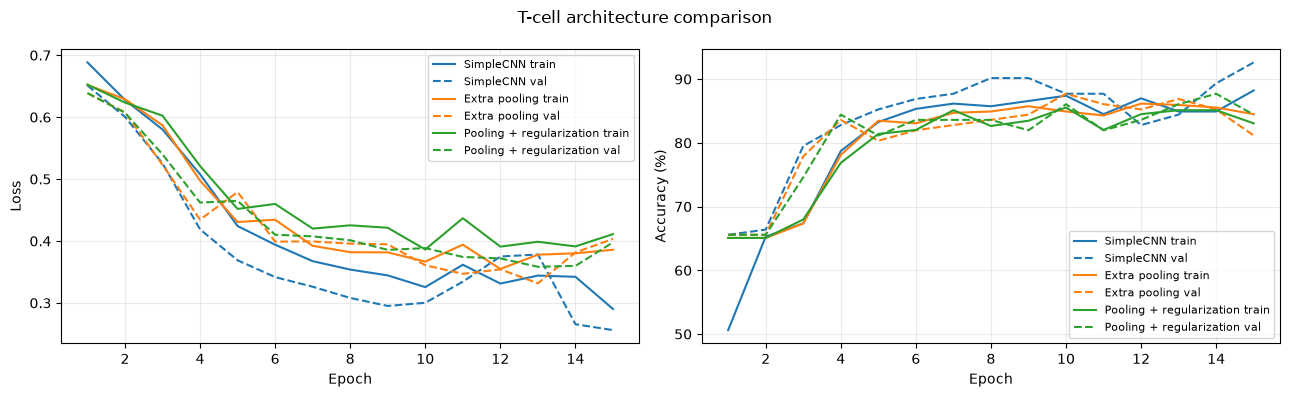

Selected: SimpleCNN, epoch 15
Final test accuracy: 91.18%
Final test ROC AUC (label 1 positive): 0.9593
Confusion matrix (rows=true, columns=predicted; label order 0,1):
[[43  1]
 [ 5 19]]


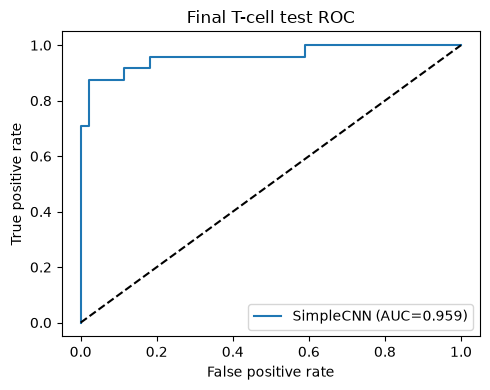

In [ ]:
# Two controlled alternatives: add pooling, then also add dropout/weight decay.
class PooledCNN(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(8 * 19 * 19, 24), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(24, 6), nn.ReLU(),
            nn.Linear(6, 1), nn.Sigmoid())
    def forward(self, x):
        return self.classifier(self.features(x))

tcell_results = {'SimpleCNN': tcell_baseline}
tcell_results['Extra pooling'] = fit_experiment(PooledCNN, train_dataset, val_dataset,
    batch_size=32, epochs=15, binary=True)
tcell_results['Pooling + regularization'] = fit_experiment(
    lambda: PooledCNN(dropout=0.3), train_dataset, val_dataset,
    batch_size=32, epochs=15, binary=True, weight_decay=1e-4)
tcell_table = results_table(tcell_results)
tcell_table['parameters'] = [sum(p.numel() for p in tcell_results[name]['model'].parameters())
                             for name in tcell_table.index]
display(tcell_table.round(4))
plot_histories(tcell_results, 'T-cell architecture comparison')
# Freeze architecture and checkpoint choice BEFORE accessing the test set.
final_name = tcell_table.index[0]
final_result = tcell_results[final_name]
final_model = final_result['model']
print(f'Selected: {final_name}, epoch {final_result["best_epoch"]}')
tcell_test_dataset = TCellDataset(X_test, y_test)
final_model.eval()
probabilities, labels = [], []
with torch.no_grad():
    for x, y_batch in DataLoader(tcell_test_dataset, batch_size=32, shuffle=False):
        probabilities.append(final_model(x.to(device)).cpu().numpy().ravel())
        labels.append(y_batch.numpy().ravel())
probabilities, labels = np.concatenate(probabilities), np.concatenate(labels)
test_predictions = (probabilities >= 0.5).astype(int)
tcell_test_acc = 100 * np.mean(test_predictions == labels)
tcell_test_auc = roc_auc_score(labels, probabilities)
print(f'Final test accuracy: {tcell_test_acc:.2f}%')
print(f'Final test ROC AUC (label 1 positive): {tcell_test_auc:.4f}')
print('Confusion matrix (rows=true, columns=predicted; label order 0,1):')
print(confusion_matrix(labels, test_predictions, labels=[0, 1]))
fpr, tpr, _ = roc_curve(labels, probabilities)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f'{final_name} (AUC={tcell_test_auc:.3f})')
plt.plot([0,1],[0,1], 'k--')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('Final T-cell test ROC'); plt.legend(); plt.tight_layout(); plt.show()

**Part C:** Discuss what you found. What neural network architecture changes did you try? What seemed to work well and what didn't work well in this application? Why do you think so?

### 3C Answer

I compared the required SimpleCNN against two variants while keeping the Adam learning rate (0.001), batch size (32), 15-epoch budget, split, and random seed fixed:

- **Extra pooling:** added a second 2×2 max-pool after the second convolution. This reduces the feature map from 8×39×39 to 8×19×19 and substantially reduces the number of dense-layer weights. It can reduce overfitting and computation, but can also discard fine spatial details.
- **Pooling + regularization:** used the same pooled network with dropout (0.3) after the first dense ReLU and Adam weight decay (0.0001). These discourage dependence on individual hidden units and large weights, but may cause underfitting with a small network or short training budget. Because both were added together, their individual effects are not isolated.

The generated discussion below reports which changes actually helped on this split. Selection uses minimum validation BCE across architectures and epochs; accuracy is also reported, but test performance does not influence selection. Training-curve values are measured during updates, whereas the summary table reevaluates the selected checkpoint in evaluation mode. This distinction matters especially for dropout. One random split and seed do not establish a statistically reliable ranking; multiple training seeds or cross-validation would be useful follow-up work.

In [ ]:
base_loss = tcell_baseline['val_loss']
lines = []
for name in ['Extra pooling', 'Pooling + regularization']:
    r = tcell_results[name]
    direction = 'improved' if r['val_loss'] < base_loss else 'did not improve'
    gap = r['train_acc'] - r['val_acc']
    lines.append(f'**{name}** {direction} validation BCE relative to the baseline '
                 f'({r["val_loss"]:.4f} versus {base_loss:.4f}); its train–validation '
                 f'accuracy gap was {gap:.2f} percentage points.')
r = final_result
lines.append(f'The selected model was **{final_name}**, at epoch {r["best_epoch"]}. '
             f'Its checkpoint training loss was **{r["train_loss"]:.4f}** and validation '
             f'loss was **{r["val_loss"]:.4f}**, with training accuracy **{r["train_acc"]:.2f}%** '
             f'and validation accuracy **{r["val_acc"]:.2f}%**. The held-out test accuracy '
             f'was **{tcell_test_acc:.2f}%** and ROC AUC was **{tcell_test_auc:.4f}**. '
             'AUC uses continuous probabilities, not thresholded predictions. The results '
             'support this choice for the current validation split; they do not prove that '
             'the same architecture will win on every sample of cells.')
display(Markdown('\n\n'.join(lines)))

**Extra pooling** did not improve validation BCE relative to the baseline (0.3317 versus 0.2561); its train–validation accuracy gap was -0.31 percentage points.

**Pooling + regularization** did not improve validation BCE relative to the baseline (0.3583 versus 0.2561); its train–validation accuracy gap was -0.94 percentage points.

The selected model was **SimpleCNN**, at epoch 15. Its checkpoint training loss was **0.2821** and validation loss was **0.2561**, with training accuracy **89.05%** and validation accuracy **92.62%**. The held-out test accuracy was **91.18%** and ROC AUC was **0.9593**. AUC uses continuous probabilities, not thresholded predictions. The results support this choice for the current validation split; they do not prove that the same architecture will win on every sample of cells.

**Interpretation of the T-cell results.** The original architecture worked best in this experiment. Extra pooling reduced the parameter count from 293,789 to 71,069, but increased both training and validation loss. That pattern is consistent with loss of useful spatial information or insufficient capacity. Adding dropout and weight decay further increased both losses, suggesting that this additional regularization was too strong for this network and training budget. These are plausible explanations, not isolated causal findings: pooling also changes dense-layer initialization and optimization, and dropout and weight decay were changed together. The baseline's validation accuracy exceeded its training accuracy, so there is no large positive train–validation accuracy gap here to motivate stronger regularization. Sampling variation and differences in split difficulty can explain that ordering. The final test set contains only 68 cells, so its accuracy and AUC have substantial sampling uncertainty.